# Cost Model

This notebook shows the cost of upgrading a dike under the two flexibility concepts of the thesis (Chapter 5).

**Retention flexibility** (Section 5.2). An upgrade from capacity $h_{i-1}$ to $h_i > h_{i-1}$ costs

$$c_a(h_{i-1}, h_i) = c + v\,(h_i - \tilde{\varphi}\, h_{i-1}),$$

with fixed cost $c$, variable cost $v$ per meter and retention flexibility $\tilde{\varphi} \in [0, 1]$, the part of the existing dike that is kept. $\tilde{\varphi} = 0$ is the inflexible dike, which is rebuilt in every upgrade. The first upgrade acts on the existing dike and uses its retention $\tilde{\varphi}_{-1}$.

**Land availability** (Section 5.3). The dike footprint grows with its height above the existing dike, $w(\Delta h) = \kappa_1 \Delta h + \kappa_2 \Delta h^2$. Open land is built up at the rate $\lambda_\mathrm{enc}$ and then costs $C_\mathrm{built}$ instead of $C_\mathrm{open}$. Land reserved up to the height $h_\mathrm{max}$ at the first decision stays open and is bought at $C_\mathrm{open}$ when needed. The land cost is added to the retention model cost (with fixed $\tilde{\varphi}$).

## Implementation

Both models are `CostModel`s (`source/cost_model.py`); `backward_induction` calls their `initial_cost_fn` (first decision) and `adapt_cost_fn` (later upgrades):

```python
cost_model = RetentionCostModel(c=10e6, v=60e6, phi_minus_1=0.8)
cost_model.adapt_cost_fn(3.0, 1.0, 5.0, 1.0)        # upgrade from 3 m to 5 m with phi = 1 [€]
land_model = LandCostModel(inner=RetentionCostModel(c=100e6, v=100e6, phi_minus_1=0.2, phi_values=(0.2,)), ...)
land_model.adapt_cost_fn(3.0, 4.0, 5.0, 5.0, t_i=20)  # 3 m -> 5 m, land secured up to 4 m, 20 years after t_0
```

The flexibility (phi or h_max) is not a parameter of the cost model but a decision, chosen in `backward_induction`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from source.cost_model import (
    LandCostModel,
    RetentionCostModel,
    plot_cost_adapt_vs_flexibility,
    plot_cost_adapt_vs_hiplus1,
    plot_open_land_width,
)

# Baseline parameters (thesis Tables 5.1 and 5.2), as in Decision_Analysis.ipynb
DIKE_TYPES = {
    "earthen": {"c": 10e6, "v": 60e6, "phi_minus_1": 0.8, "kappa_1": 10.0, "kappa_2": 1.0},
    "structurally_reinforced": {"c": 100e6, "v": 100e6, "phi_minus_1": 0.2, "kappa_1": 5.0, "kappa_2": 0.5},
}  # c [€], v [€/m], existing dike retention [-], footprint coefficients [-], [1/m]
LAND_SCENARIOS = {
    "rural": {"W_available_0": 150.0, "lambda_enc": 1.0, "C_built": 1e6},
    "urban": {"W_available_0": 100.0, "lambda_enc": 5.0, "C_built": 1e7},
}  # Open land width [m], encroachment rate [m/yr], cost of built-up land [€/m]
C_OPEN = 1e5  # Cost of open land [€/m]
LAND_DIKE_TYPE = "structurally_reinforced"
h_minus_1 = 3.0  # Existing dike capacity [m]
COST_YLIM = (0.0, 700.0)  # Common y-axis of the upgrade cost plots [M€]

## Retention Flexibility

Cost of upgrading a 3 m dike, for three values of $\tilde{\varphi}$. Every upgrade has a jump in cost of the fixed cost plus the part of the existing dike that is not retained.

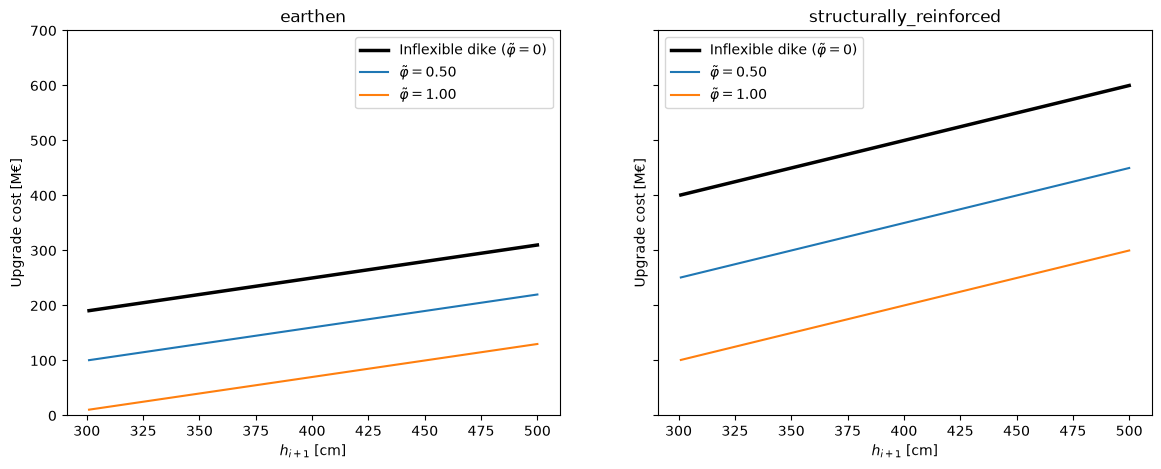

In [2]:
retention_models = {name: RetentionCostModel(c=d["c"], v=d["v"], phi_minus_1=d["phi_minus_1"]) for name, d in DIKE_TYPES.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, model) in zip(axes, retention_models.items()):
    plot_cost_adapt_vs_hiplus1(model, h_i=h_minus_1, h_i_plus_1_range=np.linspace(h_minus_1 + 0.01, h_minus_1 + 2, 100), flex_values=[0.0, 0.5, 1.0], ax=ax)
    ax.set_title(name)
axes[0].set_ylim(COST_YLIM)
plt.show()

## Land Availability

Cost of upgrading a 3 m dike once all open land is built up, for three secured heights $h_\mathrm{max}$ (3, 4 and 5 m). Within the secured height the cost is the same; above it, the land is bought at $C_\mathrm{built}$.

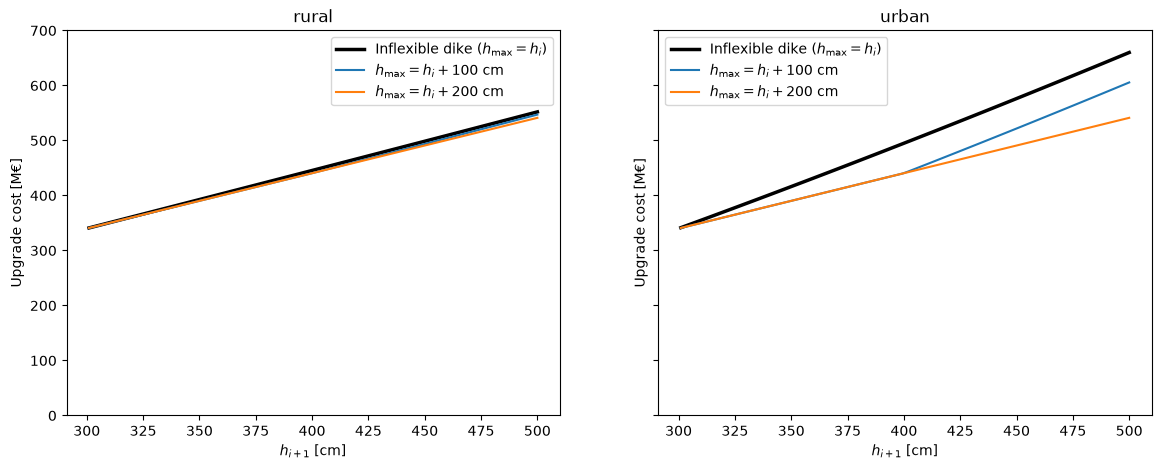

In [3]:
dike = DIKE_TYPES[LAND_DIKE_TYPE]
land_models = {
    name: LandCostModel(
        inner=RetentionCostModel(c=dike["c"], v=dike["v"], phi_minus_1=dike["phi_minus_1"], phi_values=(dike["phi_minus_1"],)),
        W_available_0=s["W_available_0"],
        lambda_enc=s["lambda_enc"],
        C_open=C_OPEN,
        C_built=s["C_built"],
        kappa_1=dike["kappa_1"],
        kappa_2=dike["kappa_2"],
        h_ref=h_minus_1,
    )
    for name, s in LAND_SCENARIOS.items()
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, model) in zip(axes, land_models.items()):
    t_built_up = model.W_available_0 / model.lambda_enc  # Years until the open land is built up
    plot_cost_adapt_vs_hiplus1(model, h_i=h_minus_1, h_i_plus_1_range=np.linspace(h_minus_1 + 0.01, h_minus_1 + 2, 100), flex_values=[0.0, 1.0, 2.0], t_i=t_built_up, ax=ax)
    ax.set_title(name)
axes[0].set_ylim(COST_YLIM)
plt.show()

Open land width over time without a reservation ($h_\mathrm{max} = h_{-1}$).

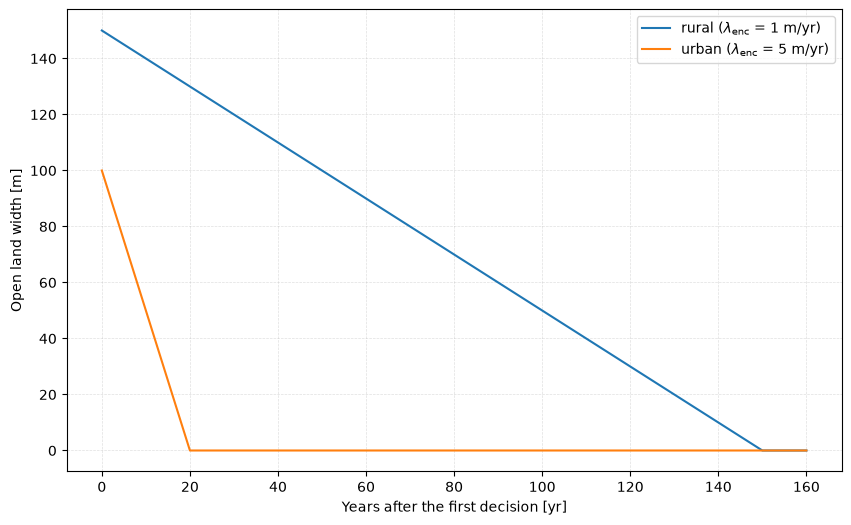

In [4]:
_ = plot_open_land_width(land_models)